In [1]:
# DAY 33 - FEATURE ENGINEERING AND FEATURE SELECTION

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("STUDENT PERFORMANCE PREDICTION SYSTEM")
print("DAY 33 - FEATURE ENGINEERING AND FEATURE SELECTION")
print("=" * 65)

print("\nLibraries imported successfully!")
print("\nToday's Objectives:")
print("1. Load the validated student dataset.")
print("2. Explore existing input features.")
print("3. Create meaningful derived features.")
print("4. Analyze feature relationships.")
print("5. Prepare a feature selection report.")

STUDENT PERFORMANCE PREDICTION SYSTEM
DAY 33 - FEATURE ENGINEERING AND FEATURE SELECTION

Libraries imported successfully!

Today's Objectives:
1. Load the validated student dataset.
2. Explore existing input features.
3. Create meaningful derived features.
4. Analyze feature relationships.
5. Prepare a feature selection report.


In [2]:
# DAY 33 - LOAD VALIDATED STUDENT DATASET

current_dir = Path.cwd()

possible_paths = [
    current_dir / "day29_validated_student_features.csv",
    current_dir.parent / "day29_validated_student_features.csv",
    current_dir.parent.parent / "day29_validated_student_features.csv",
    current_dir / "Data" / "day29_validated_student_features.csv",
    current_dir.parent / "Data" / "day29_validated_student_features.csv",
    Path(r"C:\Internship_project\Data\day29_validated_student_features.csv"),
]

dataset_path = next(
    (path for path in possible_paths if path.exists()),
    None
)

if dataset_path is not None:
    df = pd.read_csv(dataset_path)

    print("Dataset loaded successfully!")
    print("Dataset path:", dataset_path.resolve())
    print("Dataset shape:", df.shape)

    print("\nColumn Names:")
    print(df.columns.tolist())

    print("\nFirst 5 Records:")
    display(df.head())

else:
    print("Dataset file not found.")
    print("Current directory:", current_dir)
    print("Please verify the location of day29_validated_student_features.csv.")

Dataset loaded successfully!
Dataset path: C:\Users\Bagmita\OneDrive\Desktop\Project\day29_validated_student_features.csv
Dataset shape: (3, 4)

Column Names:
['study_hours', 'attendance', 'previous_score', 'assignments_completed']

First 5 Records:


,study_hours,attendance,previous_score,assignments_completed
0,6.4,91.0,57.6,8.71
1,4.2,85.5,37.8,8.82
2,4.8,87.0,43.2,8.51


In [3]:
# DAY 33 - DATASET STRUCTURE AND FEATURE CHECK

if "df" in globals() and not df.empty:

    print("=" * 60)
    print("DATASET STRUCTURE REPORT")
    print("=" * 60)

    print("\nDataset Shape:")
    print(f"Rows: {df.shape[0]}")
    print(f"Columns: {df.shape[1]}")

    print("\nColumn Information:")
    df.info()

    print("\nMissing Values:")
    display(df.isnull().sum().to_frame("Missing Count"))

    print("\nDuplicate Rows:")
    print("Total duplicate rows:", df.duplicated().sum())

    print("\nNumeric Columns:")
    numeric_columns = df.select_dtypes(
        include=np.number
    ).columns.tolist()
    print(numeric_columns)

    print("\nDescriptive Statistics:")
    display(df.describe().T)

else:
    print("Dataset unavailable or empty.")
    print("Please run Cell 2 successfully first.")

DATASET STRUCTURE REPORT

Dataset Shape:
Rows: 3
Columns: 4

Column Information:
<class 'pandas.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 4 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   study_hours            3 non-null      float64
 1   attendance             3 non-null      float64
 2   previous_score         3 non-null      float64
 3   assignments_completed  3 non-null      float64
dtypes: float64(4)
memory usage: 228.0 bytes

Missing Values:


,Missing Count
study_hours,0
attendance,0
previous_score,0
assignments_completed,0



Duplicate Rows:
Total duplicate rows: 0

Numeric Columns:
['study_hours', 'attendance', 'previous_score', 'assignments_completed']

Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max
study_hours,3.0,5.133333,1.137248,4.20,4.50,4.80,5.600,6.40
attendance,3.0,87.833333,2.843120,85.50,86.25,87.00,89.000,91.00
previous_score,3.0,46.200000,10.235233,37.80,40.50,43.20,50.400,57.60
assignments_completed,3.0,8.680000,0.157162,8.51,8.61,8.71,8.765,8.82


In [4]:
# DAY 33 - SELECT INPUT FEATURES

if "df" in globals() and not df.empty:

    expected_features = [
        "study_hours",
        "attendance",
        "previous_score",
        "assignments_completed"
    ]

    available_features = [
        col for col in expected_features
        if col in df.columns
    ]

    missing_features = [
        col for col in expected_features
        if col not in df.columns
    ]

    print("Available Input Features:")
    print(available_features)

    print("\nMissing Expected Features:")
    print(missing_features)

    if available_features:
        X_features = df[available_features].copy()

        for col in X_features.columns:
            X_features[col] = pd.to_numeric(
                X_features[col],
                errors="coerce"
            )

        X_features = X_features.replace(
            [np.inf, -np.inf],
            np.nan
        )

        print("\nSelected Feature Dataset Shape:", X_features.shape)

        print("\nFeature Preview:")
        display(X_features.head())

        print("\nFeature Data Types:")
        display(X_features.dtypes.to_frame("Data Type"))

    else:
        print("No expected input features were found.")

else:
    print("Please run Cell 2 first.")

Available Input Features:
['study_hours', 'attendance', 'previous_score', 'assignments_completed']

Missing Expected Features:
[]

Selected Feature Dataset Shape: (3, 4)

Feature Preview:


,study_hours,attendance,previous_score,assignments_completed
0,6.4,91.0,57.6,8.71
1,4.2,85.5,37.8,8.82
2,4.8,87.0,43.2,8.51



Feature Data Types:


,Data Type
study_hours,float64
attendance,float64
previous_score,float64
assignments_completed,float64


In [5]:
# DAY 33 - FEATURE ENGINEERING

if "X_features" in globals() and not X_features.empty:

    X_engineered = X_features.copy()

    # 1. Study hours per attendance point
    # Calculate only when attendance is greater than zero.
    if {"study_hours", "attendance"}.issubset(X_engineered.columns):
        X_engineered["study_attendance_ratio"] = (
            X_engineered["study_hours"] /
            X_engineered["attendance"].replace(0, np.nan)
        )

    # 2. Previous score scaled to a 0-1 proportion
    # Assumes previous_score is measured on a 0-100 scale.
    if "previous_score" in X_engineered.columns:
        X_engineered["previous_score_proportion"] = (
            X_engineered["previous_score"] / 100
        )

    # 3. Assignment completion feature
    # This is a copy of the count, not a completion rate,
    # because total assigned tasks are not available.
    if "assignments_completed" in X_engineered.columns:
        X_engineered["assignment_count_feature"] = (
            X_engineered["assignments_completed"]
        )

    print("Feature engineering completed!")

    print("\nOriginal feature count:", X_features.shape[1])
    print("Engineered feature count:", X_engineered.shape[1])

    print("\nNew Feature Names:")
    new_features = [
        col for col in X_engineered.columns
        if col not in X_features.columns
    ]
    print(new_features)

    print("\nEngineered Dataset Preview:")
    display(X_engineered.head())

else:
    print("Please run Cell 4 first to select the input features.")

Feature engineering completed!

Original feature count: 4
Engineered feature count: 7

New Feature Names:
['study_attendance_ratio', 'previous_score_proportion', 'assignment_count_feature']

Engineered Dataset Preview:


,study_hours,attendance,previous_score,assignments_completed,study_attendance_ratio,previous_score_proportion,assignment_count_feature
0,6.4,91.0,57.6,8.71,0.070330,0.576,8.71
1,4.2,85.5,37.8,8.82,0.049123,0.378,8.82
2,4.8,87.0,43.2,8.51,0.055172,0.432,8.51


In [6]:
# DAY 33 - ENGINEERED FEATURE STATISTICS

if "X_engineered" in globals() and not X_engineered.empty:

    print("=" * 65)
    print("STUDENT PERFORMANCE PREDICTION SYSTEM")
    print("DAY 33 - ENGINEERED FEATURE STATISTICS")
    print("=" * 65)

    # Generate descriptive statistics
    engineered_stats = X_engineered.describe().T

    engineered_stats["missing_values"] = (
        X_engineered.isnull().sum()
    )

    engineered_stats["unique_values"] = (
        X_engineered.nunique()
    )

    print("\nFeature Statistics:")
    display(engineered_stats.round(3))

    print("\nMissing Values by Feature:")
    display(
        X_engineered.isnull()
        .sum()
        .to_frame("Missing Count")
    )

    print("\nFeature Correlation Matrix:")
    display(
        X_engineered.corr(numeric_only=True).round(3)
    )

else:
    print("Please run Cell 5 first to create engineered features.")

STUDENT PERFORMANCE PREDICTION SYSTEM
DAY 33 - ENGINEERED FEATURE STATISTICS

Feature Statistics:


,count,mean,std,min,25%,50%,75%,max,missing_values,unique_values
study_hours,3.0,5.133,1.137,4.200,4.500,4.800,5.600,6.400,0,3
attendance,3.0,87.833,2.843,85.500,86.250,87.000,89.000,91.000,0,3
previous_score,3.0,46.200,10.235,37.800,40.500,43.200,50.400,57.600,0,3
assignments_completed,3.0,8.680,0.157,8.510,8.610,8.710,8.765,8.820,0,3
study_attendance_ratio,3.0,0.058,0.011,0.049,0.052,0.055,0.063,0.070,0,3
previous_score_proportion,3.0,0.462,0.102,0.378,0.405,0.432,0.504,0.576,0,3
assignment_count_feature,3.0,8.680,0.157,8.510,8.610,8.710,8.765,8.820,0,3



Missing Values by Feature:


,Missing Count
study_hours,0
attendance,0
previous_score,0
assignments_completed,0
study_attendance_ratio,0
previous_score_proportion,0
assignment_count_feature,0



Feature Correlation Matrix:


,study_hours,attendance,previous_score,assignments_completed,study_attendance_ratio,previous_score_proportion,assignment_count_feature
study_hours,1.000,1.000,1.000,-0.101,1.000,1.000,-0.101
attendance,1.000,1.000,1.000,-0.101,1.000,1.000,-0.101
previous_score,1.000,1.000,1.000,-0.101,1.000,1.000,-0.101
assignments_completed,-0.101,-0.101,-0.101,1.000,-0.114,-0.101,1.000
study_attendance_ratio,1.000,1.000,1.000,-0.114,1.000,1.000,-0.114
previous_score_proportion,1.000,1.000,1.000,-0.101,1.000,1.000,-0.101
assignment_count_feature,-0.101,-0.101,-0.101,1.000,-0.114,-0.101,1.000


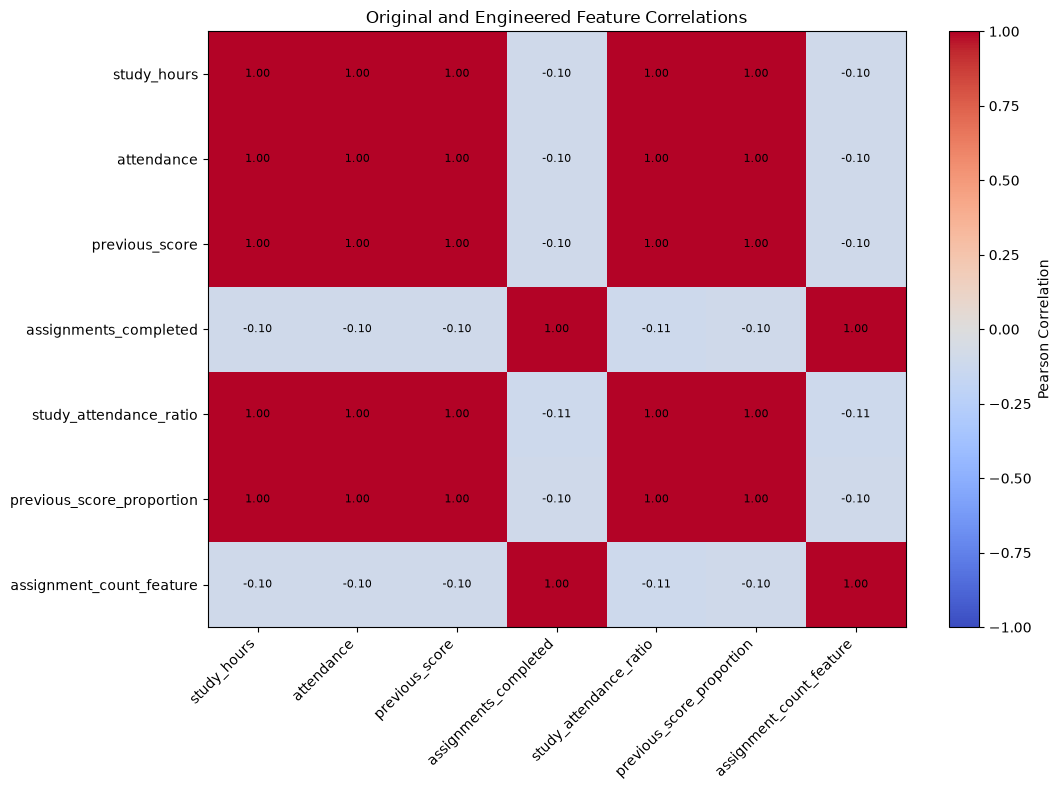


Correlation Matrix:


,study_hours,attendance,previous_score,assignments_completed,study_attendance_ratio,previous_score_proportion,assignment_count_feature
study_hours,1.000,1.000,1.000,-0.101,1.000,1.000,-0.101
attendance,1.000,1.000,1.000,-0.101,1.000,1.000,-0.101
previous_score,1.000,1.000,1.000,-0.101,1.000,1.000,-0.101
assignments_completed,-0.101,-0.101,-0.101,1.000,-0.114,-0.101,1.000
study_attendance_ratio,1.000,1.000,1.000,-0.114,1.000,1.000,-0.114
previous_score_proportion,1.000,1.000,1.000,-0.101,1.000,1.000,-0.101
assignment_count_feature,-0.101,-0.101,-0.101,1.000,-0.114,-0.101,1.000


In [7]:
# DAY 33 - FEATURE CORRELATION HEATMAP

if "X_engineered" in globals() and not X_engineered.empty:

    correlation_matrix = X_engineered.corr(numeric_only=True)

    if correlation_matrix.empty:
        print("No numeric features available for correlation analysis.")

    else:
        fig, ax = plt.subplots(figsize=(11, 8))

        image = ax.imshow(
            correlation_matrix,
            aspect="auto",
            vmin=-1,
            vmax=1,
            cmap="coolwarm"
        )

        ax.set_xticks(range(len(correlation_matrix.columns)))
        ax.set_yticks(range(len(correlation_matrix.index)))

        ax.set_xticklabels(
            correlation_matrix.columns,
            rotation=45,
            ha="right"
        )
        ax.set_yticklabels(correlation_matrix.index)

        # Display correlation values inside the heatmap
        for i in range(len(correlation_matrix.index)):
            for j in range(len(correlation_matrix.columns)):
                value = correlation_matrix.iloc[i, j]

                if pd.notna(value):
                    ax.text(
                        j,
                        i,
                        f"{value:.2f}",
                        ha="center",
                        va="center",
                        fontsize=8
                    )

        fig.colorbar(
            image,
            ax=ax,
            label="Pearson Correlation"
        )

        ax.set_title("Original and Engineered Feature Correlations")
        plt.tight_layout()
        plt.show()

        print("\nCorrelation Matrix:")
        display(correlation_matrix.round(3))

else:
    print("Please run Cell 5 first to create engineered features.")

In [8]:
# DAY 33 - HIGH CORRELATION ANALYSIS

if "X_engineered" in globals() and not X_engineered.empty:

    correlation_matrix = X_engineered.corr(numeric_only=True)

    threshold = 0.85
    high_correlation_pairs = []

    columns = correlation_matrix.columns.tolist()

    for i in range(len(columns)):
        for j in range(i + 1, len(columns)):

            corr_value = correlation_matrix.iloc[i, j]

            if pd.notna(corr_value) and abs(corr_value) >= threshold:
                high_correlation_pairs.append({
                    "feature_1": columns[i],
                    "feature_2": columns[j],
                    "correlation": corr_value,
                    "absolute_correlation": abs(corr_value)
                })

    print("High Correlation Threshold:", threshold)

    if high_correlation_pairs:

        high_corr_df = pd.DataFrame(high_correlation_pairs)
        high_corr_df = high_corr_df.sort_values(
            by="absolute_correlation",
            ascending=False
        )

        print("\nHighly Correlated Feature Pairs:")
        display(high_corr_df.round(3))

    else:
        high_corr_df = pd.DataFrame(
            columns=[
                "feature_1",
                "feature_2",
                "correlation",
                "absolute_correlation"
            ]
        )

        print("\nNo feature pairs exceeded the threshold.")

    print("\nImportant:")
    print("- High correlation indicates potential redundancy.")
    print("- It does not prove that a feature is unnecessary.")
    print("- Keep the original features until selection is justified.")
    print("- The threshold is a review guideline, not a strict rule.")

else:
    print("Please run Cell 5 first.")

High Correlation Threshold: 0.85

Highly Correlated Feature Pairs:


,feature_1,feature_2,correlation,absolute_correlation
1,study_hours,previous_score,1.0,1.0
6,attendance,previous_score_proportion,1.0,1.0
4,attendance,previous_score,1.0,1.0
9,assignments_completed,assignment_count_feature,1.0,1.0
0,study_hours,attendance,1.0,1.0
8,previous_score,previous_score_proportion,1.0,1.0
3,study_hours,previous_score_proportion,1.0,1.0
5,attendance,study_attendance_ratio,1.0,1.0
7,previous_score,study_attendance_ratio,1.0,1.0
10,study_attendance_ratio,previous_score_proportion,1.0,1.0



Important:
- High correlation indicates potential redundancy.
- It does not prove that a feature is unnecessary.
- Keep the original features until selection is justified.
- The threshold is a review guideline, not a strict rule.


In [9]:
# DAY 33 - ORIGINAL VS ENGINEERED FEATURE COMPARISON

if (
    "X_features" in globals()
    and "X_engineered" in globals()
    and not X_engineered.empty
):

    comparison_rows = []

    for col in X_engineered.columns:

        values = X_engineered[col].dropna()

        comparison_rows.append({
            "feature": col,
            "feature_type": (
                "Original"
                if col in X_features.columns
                else "Engineered"
            ),
            "non_missing_count": int(values.count()),
            "missing_count": int(X_engineered[col].isna().sum()),
            "unique_values": int(values.nunique()),
            "mean": values.mean() if not values.empty else np.nan,
            "std": values.std() if len(values) > 1 else np.nan,
            "min": values.min() if not values.empty else np.nan,
            "max": values.max() if not values.empty else np.nan
        })

    feature_comparison_df = pd.DataFrame(comparison_rows)

    print("Original and Engineered Feature Comparison:")
    display(feature_comparison_df.round(3))

    print("\nFeature Type Counts:")
    display(
        feature_comparison_df["feature_type"]
        .value_counts()
        .to_frame("Count")
    )

else:
    print("Please run Cells 4 and 5 first.")

Original and Engineered Feature Comparison:


,feature,feature_type,non_missing_count,missing_count,unique_values,mean,std,min,max
0,study_hours,Original,3,0,3,5.133,1.137,4.200,6.400
1,attendance,Original,3,0,3,87.833,2.843,85.500,91.000
2,previous_score,Original,3,0,3,46.200,10.235,37.800,57.600
3,assignments_completed,Original,3,0,3,8.680,0.157,8.510,8.820
4,study_attendance_ratio,Engineered,3,0,3,0.058,0.011,0.049,0.070
5,previous_score_proportion,Engineered,3,0,3,0.462,0.102,0.378,0.576
6,assignment_count_feature,Engineered,3,0,3,8.680,0.157,8.510,8.820



Feature Type Counts:


,Count
feature_type,
Original,4
Engineered,3


In [10]:
# DAY 33 - FEATURE SELECTION REPORT

if (
    "X_engineered" in globals()
    and "feature_comparison_df" in globals()
    and not X_engineered.empty
):

    selection_report = feature_comparison_df.copy()

    # Identify constant features
    selection_report["is_constant"] = (
        selection_report["unique_values"] <= 1
    )

    # Identify features with missing values
    selection_report["has_missing_values"] = (
        selection_report["missing_count"] > 0
    )

    print("=" * 65)
    print("FEATURE SELECTION REVIEW REPORT")
    print("=" * 65)

    display(selection_report)

    print("\nFeature Review Summary:")
    print(
        "Constant features:",
        int(selection_report["is_constant"].sum())
    )

    print(
        "Features with missing values:",
        int(selection_report["has_missing_values"].sum())
    )

    print("\nHigh-Correlation Feature Pairs:")
    if "high_corr_df" in globals() and not high_corr_df.empty:
        display(high_corr_df)
    else:
        print("No high-correlation pairs were identified.")

    print("\nReview Guidelines:")
    print("1. Investigate constant features.")
    print("2. Investigate missing values before modelling.")
    print("3. Review redundant feature pairs using domain knowledge.")
    print("4. Do not remove features based only on correlation.")
    print("5. Validate predictive usefulness using genuine outcome labels.")

else:
    print("Please run Cells 5, 8, and 9 first.")

FEATURE SELECTION REVIEW REPORT


,feature,feature_type,non_missing_count,missing_count,unique_values,mean,std,min,max,is_constant,has_missing_values
0,study_hours,Original,3,0,3,5.133333,1.137248,4.200000,6.40000,False,False
1,attendance,Original,3,0,3,87.833333,2.843120,85.500000,91.00000,False,False
2,previous_score,Original,3,0,3,46.200000,10.235233,37.800000,57.60000,False,False
3,assignments_completed,Original,3,0,3,8.680000,0.157162,8.510000,8.82000,False,False
4,study_attendance_ratio,Engineered,3,0,3,0.058208,0.010925,0.049123,0.07033,False,False
5,previous_score_proportion,Engineered,3,0,3,0.462000,0.102352,0.378000,0.57600,False,False
6,assignment_count_feature,Engineered,3,0,3,8.680000,0.157162,8.510000,8.82000,False,False



Feature Review Summary:
Constant features: 0
Features with missing values: 0

High-Correlation Feature Pairs:


,feature_1,feature_2,correlation,absolute_correlation
1,study_hours,previous_score,1.000000,1.000000
6,attendance,previous_score_proportion,1.000000,1.000000
4,attendance,previous_score,1.000000,1.000000
9,assignments_completed,assignment_count_feature,1.000000,1.000000
0,study_hours,attendance,1.000000,1.000000
8,previous_score,previous_score_proportion,1.000000,1.000000
3,study_hours,previous_score_proportion,1.000000,1.000000
5,attendance,study_attendance_ratio,0.999908,0.999908
7,previous_score,study_attendance_ratio,0.999908,0.999908
10,study_attendance_ratio,previous_score_proportion,0.999908,0.999908



Review Guidelines:
1. Investigate constant features.
2. Investigate missing values before modelling.
3. Review redundant feature pairs using domain knowledge.
4. Do not remove features based only on correlation.
5. Validate predictive usefulness using genuine outcome labels.


In [11]:
# DAY 33 - SAVE ENGINEERED FEATURES AND SELECTION REPORT

if (
    "X_engineered" in globals()
    and "selection_report" in globals()
    and not X_engineered.empty
):

    output_dir = Path.cwd()
    output_dir.mkdir(parents=True, exist_ok=True)

    engineered_path = (
        output_dir / "day33_engineered_student_features.csv"
    )

    selection_path = (
        output_dir / "day33_feature_selection_report.csv"
    )

    correlation_path = (
        output_dir / "day33_feature_correlation_matrix.csv"
    )

    # Save engineered features
    X_engineered.to_csv(
        engineered_path,
        index=False
    )

    # Save feature selection review report
    selection_report.to_csv(
        selection_path,
        index=False
    )

    # Save correlation matrix
    X_engineered.corr(numeric_only=True).to_csv(
        correlation_path
    )

    print("Day 33 files saved successfully!\n")

    print("Engineered Features:")
    print(engineered_path.resolve())

    print("\nFeature Selection Report:")
    print(selection_path.resolve())

    print("\nCorrelation Matrix:")
    print(correlation_path.resolve())

else:
    print("Please run the previous cells successfully first.")

Day 33 files saved successfully!

Engineered Features:
C:\Users\Bagmita\OneDrive\Desktop\Project\day33_engineered_student_features.csv

Feature Selection Report:
C:\Users\Bagmita\OneDrive\Desktop\Project\day33_feature_selection_report.csv

Correlation Matrix:
C:\Users\Bagmita\OneDrive\Desktop\Project\day33_feature_correlation_matrix.csv


In [12]:
# DAY 33 - FINAL VERIFICATION

print("=" * 65)
print("STUDENT PERFORMANCE PREDICTION SYSTEM")
print("DAY 33 - FINAL VERIFICATION")
print("=" * 65)

if "X_engineered" in globals() and not X_engineered.empty:

    print("\n1. Engineered Dataset")
    print("Rows:", X_engineered.shape[0])
    print("Columns:", X_engineered.shape[1])
    print("Feature names:", X_engineered.columns.tolist())

    print("\n2. Missing Values")
    display(
        X_engineered.isnull()
        .sum()
        .to_frame("Missing Count")
    )

    print("\n3. Saved File Verification")

    expected_files = [
        "day33_engineered_student_features.csv",
        "day33_feature_selection_report.csv",
        "day33_feature_correlation_matrix.csv"
    ]

    for filename in expected_files:
        file_path = Path.cwd() / filename

        if file_path.exists():
            print(f"[SAVED] {filename}")
        else:
            print(f"[NOT FOUND] {filename}")

    print("\n4. Final Notes")
    print("- Original input features were preserved.")
    print("- Derived features were created for exploration.")
    print("- Correlation was reviewed for possible redundancy.")
    print("- No features were automatically removed.")
    print("- Actual outcome labels are required to assess")
    print("  predictive performance.")

    print("\nDay 33 feature engineering workflow completed!")

else:
    print("Engineered dataset is unavailable.")
    print("Please run Cells 2-11 in order.")

STUDENT PERFORMANCE PREDICTION SYSTEM
DAY 33 - FINAL VERIFICATION

1. Engineered Dataset
Rows: 3
Columns: 7
Feature names: ['study_hours', 'attendance', 'previous_score', 'assignments_completed', 'study_attendance_ratio', 'previous_score_proportion', 'assignment_count_feature']

2. Missing Values


,Missing Count
study_hours,0
attendance,0
previous_score,0
assignments_completed,0
study_attendance_ratio,0
previous_score_proportion,0
assignment_count_feature,0



3. Saved File Verification
[SAVED] day33_engineered_student_features.csv
[SAVED] day33_feature_selection_report.csv
[SAVED] day33_feature_correlation_matrix.csv

4. Final Notes
- Original input features were preserved.
- Derived features were created for exploration.
- Correlation was reviewed for possible redundancy.
- No features were automatically removed.
- Actual outcome labels are required to assess
  predictive performance.

Day 33 feature engineering workflow completed!
